# L2_T6 — Final Validation, Operating Point, Model Card and Release Package
### Layer 2 of the Aura pipeline · Task 6 (last)

**What this notebook does.** Closes Layer 2 the way `L1_T6` closed Layer 1: checks every artifact, puts every result
in one honest ledger, tunes the **decision rule** for the `none_of_these` class without retraining, writes the
app-facing contract and a model card, evaluates a release gate, and packages everything with checksums.

**No GPU needed** — CPU runtime is fine. Nothing here trains a model.

**What this notebook will and won't say.** At the end of T5 the model missed about a quarter of real conditions and
had no clear-skin or Filipino test. This notebook does not hide that. It produces a **research package**, and the
release gate will state plainly whether the model is allowed anywhere near users.

**The one thing it can improve:** T5 predicted `none_of_these` whenever it was the top class. That rule is a default,
not a choice. Using T5's saved out-of-fold probabilities, Step 3 picks a better cut-off for "none" — and estimates how
well that choice generalises with **nested validation** (the cut-off is chosen on four folds and scored on the fifth),
so the improvement isn't just fitted to the numbers it's reported on.

**Honest limits:** ~98 in-scope cases means every in-scope number is directional. The cut-off chosen here is
tuned on SCIN; it must be re-chosen on your own selfie data before any real use.

## Step 0 — Mount Drive and load the Layer 2 manifest

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, time, shutil, tarfile, hashlib, datetime

DRIVE_ROOT = "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition"
MANIFEST_PATH = f"{DRIVE_ROOT}/manifest.json"
assert os.path.exists(MANIFEST_PATH), "manifest.json not found"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)
for k in ("preprocessing", "model_training", "selfie_gap_eval", "none_class_v2"):
    assert k in manifest, f"manifest missing '{k}' -- did that task finish?"
print("✅ Manifest has all prior-task sections.")

DRIVE_MODEL_DIR = f"{DRIVE_ROOT}/models"
DRIVE_EVAL_DIR = f"{DRIVE_ROOT}/evaluation"
DRIVE_RELEASE_DIR = f"{DRIVE_ROOT}/release"
os.makedirs(DRIVE_RELEASE_DIR, exist_ok=True)
LOCAL_ROOT = "/content/aura_local/Layer2_SkinCondition"
LOCAL_REL = f"{LOCAL_ROOT}/release_pkg"
shutil.rmtree(LOCAL_REL, ignore_errors=True); os.makedirs(LOCAL_REL)


Mounted at /content/drive
✅ Manifest has all prior-task sections.


## Step 1 — Artifact inventory and integrity

In [ ]:
import pandas as pd, numpy as np

EXPECTED = {
    "T3 baseline (Keras)":      f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.keras",
    "T3 baseline (TFLite)":     f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.tflite",
    "T3 labels":                f"{DRIVE_MODEL_DIR}/aura_l2_condition_labels.json",
    "T5 v2 model (Keras)":      f"{DRIVE_MODEL_DIR}/aura_l2_condition_v2_none.keras",
    "T5 v2 model (TFLite)":     f"{DRIVE_MODEL_DIR}/aura_l2_condition_v2_none.tflite",
    "T5 v2 labels":             f"{DRIVE_MODEL_DIR}/aura_l2_condition_v2_none_labels.json",
    "T4 SCIN results":          f"{DRIVE_EVAL_DIR}/scin_eval_results.csv",
    "T5 CV results (per case)": f"{DRIVE_EVAL_DIR}/scin_cv_results_t5.csv",
    "T5 CV subgroups":          f"{DRIVE_EVAL_DIR}/scin_cv_subgroups_t5.csv",
    "T5 CV abstention":         f"{DRIVE_EVAL_DIR}/scin_cv_abstention_t5.csv",
    "T4 provenance notice":     f"{DRIVE_EVAL_DIR}/DATA_PROVENANCE_L2_T4.md",
    "T5 provenance notice":     f"{DRIVE_EVAL_DIR}/DATA_PROVENANCE_L2_T5.md",
    "DermNet preprocessed set": manifest["preprocessing"]["drive_archive"],
}
rows, missing = [], []
for name, p in EXPECTED.items():
    ok = os.path.exists(p)
    rows.append({"artifact": name, "present": "✅" if ok else "❌ MISSING", "size_MB": round(os.path.getsize(p) / 1e6, 2) if ok else None})
    if not ok: missing.append(name)
print(pd.DataFrame(rows).to_string(index=False))
assert not missing, f"Missing artifacts: {missing}. Re-run the task that produces them."

t3_classes = json.load(open(EXPECTED["T3 labels"]))["classes"]
v2_meta = json.load(open(EXPECTED["T5 v2 labels"]))
v2_classes = v2_meta["classes"]
assert v2_classes[:3] == t3_classes and v2_classes[3] == "none_of_these", f"Label order mismatch: {t3_classes} vs {v2_classes}"
print("\n✅ Label order consistent: v2 =", v2_classes)
CLASSES = v2_classes; NONE_IDX = 3


                artifact present  size_MB
     T3 baseline (Keras)       ✅    27.84
    T3 baseline (TFLite)       ✅     4.57
               T3 labels       ✅     0.00
     T5 v2 model (Keras)       ✅    28.97
    T5 v2 model (TFLite)       ✅     4.57
            T5 v2 labels       ✅     0.00
         T4 SCIN results       ✅     0.23
T5 CV results (per case)       ✅     0.33
         T5 CV subgroups       ✅     0.00
        T5 CV abstention       ✅     0.00
    T4 provenance notice       ✅     0.00
    T5 provenance notice       ✅     0.00
DermNet preprocessed set       ✅    22.84

✅ Label order consistent: v2 = ['acne', 'pigmentation', 'redness_sensitivity', 'none_of_these']


## Step 2 — The results ledger: every number, what it measures, and what it can't tell you
Three different numbers have been quoted across Layer 2. They are **not comparable** — different data, different task
(3-way vs 4-way). This table keeps them from being mixed up.

In [ ]:
mt, t4, t5 = manifest["model_training"], manifest["selfie_gap_eval"], manifest["none_class_v2"]
ledger = pd.DataFrame([
    {"task": "L2_T3", "model": "3-class baseline", "data": "DermNet clinical test split (n=171)",
     "headline": f"accuracy {mt['test_accuracy']:.3f}, macro F1 {mt['test_macro_f1']:.3f}",
     "what_it_means": "Pipeline works on easy clinical close-ups",
     "what_it_cannot_say": "Anything about phone photos, skin tone, or clear skin"},
    {"task": "L2_T4", "model": "3-class baseline", "data": f"SCIN in-scope (n={t4['in_scope_cases']})",
     "headline": f"accuracy {t4['scin_accuracy']:.3f} (CI {t4['scin_accuracy_ci95'][0]:.2f}-{t4['scin_accuracy_ci95'][1]:.2f}); majority {t4['majority_baseline']:.2f}",
     "what_it_means": "Does not transfer to phone photos; ~= guessing the majority class",
     "what_it_cannot_say": "Selfie performance (cases are conditions, mostly not faces)"},
    {"task": "L2_T5", "model": "4-class + none_of_these", "data": f"SCIN 5-fold CV (in {t5['in_scope_cases']}, other {t5['out_of_scope_cases']})",
     "headline": f"other conditions rejected {t5['cv_oos_rejection']:.3f}; in-scope accuracy {t5['cv_inscope_accuracy']:.3f}; real cases called 'none' {t5['inscope_called_none']:.3f}",
     "what_it_means": "Fixed false alarms on unrelated conditions; still misses a quarter of real ones",
     "what_it_cannot_say": "Clear-skin behaviour, Filipino skin tones, FST V-VI in-scope accuracy"},
])
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 250)
for _, r in ledger.iterrows():
    print(f"[{r.task}] {r.model} -- {r.data}\n   headline:  {r.headline}\n   means:     {r.what_it_means}\n   cannot say: {r.what_it_cannot_say}\n")


[L2_T3] 3-class baseline -- DermNet clinical test split (n=171)
   headline:  accuracy 0.754, macro F1 0.743
   means:     Pipeline works on easy clinical close-ups
   cannot say: Anything about phone photos, skin tone, or clear skin

[L2_T4] 3-class baseline -- SCIN in-scope (n=102)
   headline:  accuracy 0.520 (CI 0.42-0.62); majority 0.50
   means:     Does not transfer to phone photos; ~= guessing the majority class
   cannot say: Selfie performance (cases are conditions, mostly not faces)

[L2_T5] 4-class + none_of_these -- SCIN 5-fold CV (in 98, other 2126)
   headline:  other conditions rejected 0.928; in-scope accuracy 0.459; real cases called 'none' 0.255
   means:     Fixed false alarms on unrelated conditions; still misses a quarter of real ones
   cannot say: Clear-skin behaviour, Filipino skin tones, FST V-VI in-scope accuracy



## Step 3 — Operating point for `none_of_these` (no retraining)
T5 predicted "none" whenever it was the top class. Here the rule is: **predict `none_of_these` only if its probability
is ≥ τ; otherwise pick the best of the three conditions.** τ trades two errors against each other:
- low τ → more unrelated conditions rejected, but more *real* conditions wrongly rejected;
- high τ → fewer real conditions rejected, but more unrelated ones get a condition label.

τ is chosen to maximise the balanced score (mean of in-scope accuracy and unrelated-condition rejection), subject to
real cases called "none" staying ≤ 20%. **Nested validation** estimates how this choice generalises: for each fold, τ is
chosen on the other four folds and scored on the held-out one.

Cases: 2224 (in-scope 98, other conditions 2126)

T5 default rule (argmax): {'inscope_acc': 0.459, 'inscope_called_none': 0.255, 'oos_rejection': 0.928, 'balanced': 0.693}

τ sweep (descriptive -- fitted on the same data, so optimistic):
 tau  inscope_acc  inscope_called_none  oos_rejection  balanced
0.05        0.286                0.592          0.986     0.636
0.10        0.378                0.429          0.977     0.677
0.15        0.388                0.388          0.971     0.680
0.20        0.429                0.327          0.967     0.698
0.25        0.439                0.306          0.961     0.700
0.30        0.449                0.276          0.956     0.702
0.35        0.449                0.265          0.947     0.698
0.40        0.459                0.255          0.936     0.698
0.45        0.480                0.235          0.925     0.702
0.50        0.541                0.173          0.910     0.725
0.55        0.582                0.133          0.897     

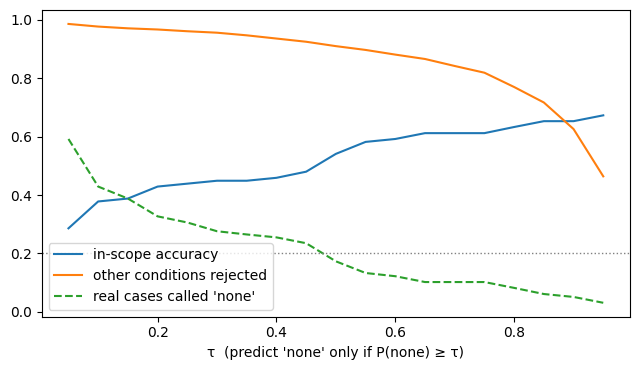


τ chosen per fold (stability check): {1: 0.65, 2: 0.65, 3: 0.55, 4: 0.55, 5: 0.65}
NESTED (honest) estimate: {'inscope_acc': 0.582, 'inscope_called_none': 0.133, 'oos_rejection': 0.88, 'balanced': 0.731}
T5 default             : {'inscope_acc': 0.459, 'inscope_called_none': 0.255, 'oos_rejection': 0.928, 'balanced': 0.693}
Nested in-scope accuracy CI95: 0.490-0.673 | other-condition rejection CI95: 0.865-0.893

τ recommended for the research package (chosen on all OOF data): 0.55
τ spread across folds: 0.10  ->  stable enough


In [ ]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

oof = pd.read_csv(EXPECTED["T5 CV results (per case)"])
oof["case_id"] = oof["case_id"].astype(str)
for c in ("is_asian", "head_neck"):
    oof[c] = oof[c].astype(str).str.lower().isin(["true", "1", "yes"])
assert all(c in oof.columns for c in CLASSES), "Probability columns missing from T5 results CSV"
P = oof[CLASSES].values
oof["y"] = oof["true_cat"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)
print(f"Cases: {len(oof)} (in-scope {(oof.y < NONE_IDX).sum()}, other conditions {(oof.y == NONE_IDX).sum()})")

def decide(P, tau):
    return np.where(P[:, NONE_IDX] >= tau, NONE_IDX, P[:, :NONE_IDX].argmax(1))

def metrics(y, pred):
    ins, oos = y < NONE_IDX, y == NONE_IDX
    a = float((pred[ins] == y[ins]).mean()); cn = float((pred[ins] == NONE_IDX).mean()); rj = float((pred[oos] == NONE_IDX).mean())
    return {"inscope_acc": a, "inscope_called_none": cn, "oos_rejection": rj, "balanced": (a + rj) / 2}

TAUS = np.round(np.arange(0.05, 0.96, 0.05), 2)
MAX_CALLED_NONE = 0.20
def pick_tau(y, P):
    best, best_score = None, -1
    for t in TAUS:
        m = metrics(y, decide(P, t))
        if m["inscope_called_none"] <= MAX_CALLED_NONE and m["balanced"] > best_score:
            best, best_score = t, m["balanced"]
    if best is None:  # constraint unattainable -> fall back to best balanced overall
        best = max(TAUS, key=lambda t: metrics(y, decide(P, t))["balanced"])
    return float(best)

# Sweep over all data (descriptive, optimistic)
sweep = pd.DataFrame([{"tau": t, **metrics(oof.y.values, decide(P, t))} for t in TAUS]).round(3)
default = metrics(oof.y.values, P.argmax(1))
print("\nT5 default rule (argmax):", {k: round(v, 3) for k, v in default.items()})
print("\nτ sweep (descriptive -- fitted on the same data, so optimistic):")
print(sweep.to_string(index=False))

plt.figure(figsize=(6.5, 3.8))
plt.plot(sweep.tau, sweep.inscope_acc, label="in-scope accuracy")
plt.plot(sweep.tau, sweep.oos_rejection, label="other conditions rejected")
plt.plot(sweep.tau, sweep.inscope_called_none, label="real cases called 'none'", linestyle="--")
plt.axhline(MAX_CALLED_NONE, color="gray", linestyle=":", linewidth=1)
plt.xlabel("τ  (predict 'none' only if P(none) ≥ τ)"); plt.legend(); plt.tight_layout(); plt.show()

# Nested validation: choose τ on 4 folds, score on the 5th
folds = sorted(oof["fold"].unique()); nested_pred = np.zeros(len(oof), dtype=int); chosen = {}
for f in folds:
    tr, te = (oof.fold != f).values, (oof.fold == f).values
    chosen[int(f)] = pick_tau(oof.y.values[tr], P[tr])
    nested_pred[te] = decide(P[te], chosen[int(f)])
nested = metrics(oof.y.values, nested_pred)
print("\nτ chosen per fold (stability check):", chosen)
print("NESTED (honest) estimate:", {k: round(v, 3) for k, v in nested.items()})
print("T5 default             :", {k: round(v, 3) for k, v in default.items()})

ins_m, oos_m = (oof.y < NONE_IDX).values, (oof.y == NONE_IDX).values
def boot(mask, pred, target, n=1000):
    idx = np.where(mask)[0]; vals = []
    for _ in range(n):
        s = rng.choice(idx, len(idx)); vals.append(float((pred[s] == target(s)).mean()))
    return np.percentile(vals, [2.5, 97.5])
ci_acc = boot(ins_m, nested_pred, lambda s: oof.y.values[s])
ci_rej = boot(oos_m, nested_pred, lambda s: np.full(len(s), NONE_IDX))
print(f"Nested in-scope accuracy CI95: {ci_acc[0]:.3f}-{ci_acc[1]:.3f} | other-condition rejection CI95: {ci_rej[0]:.3f}-{ci_rej[1]:.3f}")

TAU_FINAL = pick_tau(oof.y.values, P)
final_pred = decide(P, TAU_FINAL)
print(f"\nτ recommended for the research package (chosen on all OOF data): {TAU_FINAL}")
spread = max(chosen.values()) - min(chosen.values())
print(f"τ spread across folds: {spread:.2f}  ->  " + ("stable enough" if spread <= 0.20 else "UNSTABLE: treat τ as unreliable until there is more data"))


**How to read this:** compare the **nested** line to the T5 default. If the improvement is small or τ jumps around
between folds, the data (~98 real cases) is too thin to tune on and that's the finding, not a failure of the method.

## Step 4 — The cost of τ on the groups that matter: face region and skin tone

In [ ]:
oof["final_pred"] = final_pred
oof["rejected"] = oof["final_pred"] == NONE_IDX
oof["default_rejected"] = P.argmax(1) == NONE_IDX
oos_df, ins_df = oof[oof.y == NONE_IDX], oof[oof.y < NONE_IDX]
MIN_N = 30
rows = []
def grp(name, mo, mi):
    o, i = oos_df[mo], ins_df[mi]
    rows.append({"group": name, "n_other": len(o), "rejection_default": round(float(o.default_rejected.mean()), 3) if len(o) else None,
                 "rejection_at_tau": round(float(o.rejected.mean()), 3) if len(o) else None,
                 "n_inscope": len(i), "inscope_acc_at_tau": round(float((i.final_pred == i.y).mean()), 3) if len(i) else None,
                 "inscope_reliable": "OK" if len(i) >= MIN_N else "UNRELIABLE (n<30)"})
T = lambda d: np.ones(len(d), dtype=bool)
grp("All", T(oos_df), T(ins_df))
grp("Head/neck (selfie proxy)", oos_df.head_neck.values, ins_df.head_neck.values)
grp("Not head/neck", ~oos_df.head_neck.values, ~ins_df.head_neck.values)
for g in ["FST I-II", "FST III-IV", "FST V-VI"]:
    grp(g, (oos_df.fst_group == g).values, (ins_df.fst_group == g).values)
grp("Asian-flagged", oos_df.is_asian.values, ins_df.is_asian.values)
grp_df = pd.DataFrame(rows); print(grp_df.to_string(index=False))
print("\nOnly quote in-scope accuracy for rows marked OK. Rejection rows have large n and are usable.")


                   group  n_other  rejection_default  rejection_at_tau  n_inscope  inscope_acc_at_tau  inscope_reliable
                     All     2126              0.928             0.897         98               0.582                OK
Head/neck (selfie proxy)      247              0.713             0.680         54               0.574                OK
           Not head/neck     1879              0.956             0.926         44               0.591                OK
                FST I-II      799              0.920             0.897         43               0.651                OK
              FST III-IV      965              0.938             0.909         40               0.550                OK
                FST V-VI      176              0.898             0.847         12               0.417 UNRELIABLE (n<30)
           Asian-flagged       38              0.921             0.921          4               0.750 UNRELIABLE (n<30)

Only quote in-scope accuracy for rows m

## Step 5 — Smoke test of the shipping TFLite
A **plumbing check, not an accuracy test.** It confirms the exported file loads, returns valid probabilities, isn't
degenerate, and gives a rough CPU latency. It runs on DermNet images the model trained on, so its predictions say nothing
about real-world accuracy.

In [ ]:
import tensorflow as tf
try:
    from ai_edge_litert.interpreter import Interpreter
except Exception:
    Interpreter = tf.lite.Interpreter

local_arch = f"{LOCAL_ROOT}/dermnet_pp.tar.gz"
shutil.copy2(manifest["preprocessing"]["drive_archive"], local_arch)
DN_ROOT = f"{LOCAL_ROOT}/dn_smoke"; shutil.rmtree(DN_ROOT, ignore_errors=True); os.makedirs(DN_ROOT)
with tarfile.open(local_arch, "r:gz") as tar: tar.extractall(DN_ROOT, filter="data")
DN_DIR = f"{DN_ROOT}/dermnet_conditions_preprocessed"
dn = pd.read_csv(f"{DN_DIR}/processed_labels.csv").sample(60, random_state=3)

tfl = f"{LOCAL_ROOT}/v2.tflite"; shutil.copy2(EXPECTED["T5 v2 model (TFLite)"], tfl)
it = Interpreter(model_path=tfl); it.allocate_tensors()
i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]
print("Input:", i_d["shape"], i_d["dtype"].__name__, "| Output:", o_d["shape"])
assert tuple(o_d["shape"][-1:]) == (4,), "Output is not 4-way"

outs, times = [], []
for fn in dn["processed_filename"]:
    x = tf.cast(tf.image.decode_jpeg(tf.io.read_file(f"{DN_DIR}/{fn}"), channels=3), tf.float32).numpy()[None]
    t0 = time.perf_counter(); it.set_tensor(i_d["index"], x.astype("float32")); it.invoke()
    outs.append(it.get_tensor(o_d["index"])[0].copy()); times.append((time.perf_counter() - t0) * 1000)
O = np.stack(outs)
checks = [("no NaN/Inf", bool(np.isfinite(O).all())),
          ("each row sums to ~1", bool(np.allclose(O.sum(1), 1, atol=1e-2))),
          ("not degenerate (uses >=2 classes)", len(set(O.argmax(1))) >= 2)]
for n, ok in checks: print(("  ✅ " if ok else "  ❌ ") + n)
assert all(ok for _, ok in checks), "TFLite smoke test failed -- do not package this model."
print(f"Predicted-class mix on 60 images: {dict(zip(CLASSES, np.bincount(O.argmax(1), minlength=4).tolist()))}")
print(f"CPU latency per image: median {np.median(times):.1f} ms, p95 {np.percentile(times, 95):.1f} ms (this Colab CPU; phones differ)")
LATENCY_MS = float(np.median(times))


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input: [  1 224 224   3] float32 | Output: [1 4]
  ✅ no NaN/Inf
  ✅ each row sums to ~1
  ✅ not degenerate (uses >=2 classes)
Predicted-class mix on 60 images: {'acne': 16, 'pigmentation': 18, 'redness_sensitivity': 25, 'none_of_these': 1}
CPU latency per image: median 36.9 ms, p95 43.1 ms (this Colab CPU; phones differ)


## Step 6 — The app-facing contract (`inference_config.json`)
Everything the app needs to call the model **exactly as it was trained and evaluated** — preprocessing, label order,
decision rule, and the rules for what may be shown to a user.

In [ ]:
inference_config = {
    "model_file": "aura_l2_condition_v2_none.tflite",
    "version": "v0-research",
    "status": "RESEARCH ONLY -- not approved for end users",
    "classes": CLASSES,
    "input": {
        "shape": [1, 224, 224, 3], "dtype": "float32", "channel_order": "RGB", "value_range": "0-255 (the model rescales internally; do NOT divide by 255)",
        "preprocessing_order": [
            "Detect face with MediaPipe BlazeFace short-range (blaze_face_short_range.tflite)",
            "If a face is found: crop its bounding box with a 25% margin on each side; otherwise use the whole image",
            "Resize to 224x224 with area interpolation (cv2.INTER_AREA)",
            "Convert to LAB, apply CLAHE (clipLimit 2.0, tileGridSize 8x8) to the L channel only, convert back to RGB",
            "Encode/decode as JPEG quality 92 (training images were stored this way); skip only if verified to make no difference",
        ],
    },
    "output": "softmax probabilities over `classes`, in the order listed",
    "decision_rule": {
        "description": "Predict none_of_these if P(none_of_these) >= tau; otherwise the highest-probability condition among the first three classes.",
        "tau": TAU_FINAL,
        "tau_source": "chosen on SCIN out-of-fold probabilities (5-fold CV); nested estimate in manifest.final_validation",
        "tau_must_be_rechosen_on": "own consented selfie data before any real use",
    },
    "ui_policy": [
        "Never present a result as a diagnosis, a medical finding, or a numeric skin score.",
        "none_of_these means 'not one of the three conditions seen in training' -- it does NOT mean healthy skin.",
        "Show a hedged, non-clinical message and a 'not sure' state; never show raw probabilities.",
        "Do not use this model's output to filter, rank or exclude users, or to recommend treatment.",
    ],
    "known_failure_modes": [
        "About a quarter of real acne/redness/pigmentation cases are called none_of_these.",
        "Face-region photos: unrelated conditions are rejected less often than in body-region photos.",
        "Pigmentation was never predicted correctly in cross-validation (n=10).",
        "Clear-skin faces and Filipino skin tones have not been tested.",
    ],
    "measured_cpu_latency_ms": round(LATENCY_MS, 1),
}
with open(f"{LOCAL_REL}/inference_config.json", "w") as f:
    json.dump(inference_config, f, indent=2)
print(json.dumps({k: inference_config[k] for k in ("status", "classes", "decision_rule")}, indent=2))


{
  "status": "RESEARCH ONLY -- not approved for end users",
  "classes": [
    "acne",
    "pigmentation",
    "redness_sensitivity",
    "none_of_these"
  ],
  "decision_rule": {
    "description": "Predict none_of_these if P(none_of_these) >= tau; otherwise the highest-probability condition among the first three classes.",
    "tau": 0.55,
    "tau_source": "chosen on SCIN out-of-fold probabilities (5-fold CV); nested estimate in manifest.final_validation",
    "tau_must_be_rechosen_on": "own consented selfie data before any real use"
  }
}


## Step 7 — Release gate
Targets are project goals, not clinical standards. **Read the verdict line**, and the blockers under it.

In [ ]:
def S(v): return "PASS" if v is True else ("FAIL" if v is False else "UNKNOWN")
gate = []
gate.append(("Other conditions rejected >= 0.85 (nested)", bool(nested["oos_rejection"] >= 0.85), f"{nested['oos_rejection']:.3f}"))
gate.append(("In-scope accuracy >= 0.70 (nested)", bool(nested["inscope_acc"] >= 0.70), f"{nested['inscope_acc']:.3f}"))
gate.append(("Real cases called 'none' <= 0.15 (nested)", bool(nested["inscope_called_none"] <= 0.15), f"{nested['inscope_called_none']:.3f}"))
r = grp_df.set_index("group")
ht = r.loc["Head/neck (selfie proxy)", "rejection_at_tau"]
gate.append(("Face-region rejection >= 0.85", bool(ht >= 0.85), f"{ht:.3f}"))
a, b = r.loc["FST I-II", "rejection_at_tau"], r.loc["FST V-VI", "rejection_at_tau"]
gate.append(("Rejection gap FST I-II vs V-VI <= 0.10", bool(abs(a - b) <= 0.10), f"{a - b:+.3f}"))
v6 = r.loc["FST V-VI", "n_inscope"]
gate.append(("In-scope accuracy measurable for FST V-VI (n>=30)", bool(v6 >= 30), f"n={int(v6)}"))
gate.append(("Clear-skin selfie test exists", None, "no such data collected"))
gate.append(("Filipino-skin evaluation exists", None, "no such data collected"))
gate.append(("All training data licenses cleared for commercial use", None, "DermNet mirror states no license; SCIN license needs review"))
for n, ok, v in gate: print(f"  {S(ok):8s} {n}  [{v}]")

n_fail = sum(1 for _, ok, _ in gate if ok is False); n_unk = sum(1 for _, ok, _ in gate if ok is None)
VERDICT = "NOT PRODUCTION-READY (research checkpoint)" if (n_fail or n_unk) else "ELIGIBLE FOR LIMITED PILOT REVIEW"
print(f"\nVERDICT: {VERDICT}   ({n_fail} failed, {n_unk} unknown, {len(gate) - n_fail - n_unk} passed)")
BLOCKERS = [
    "200+ consented, dermatologist-labelled selfies per condition (acne, redness/sensitivity, pigmentation)",
    "A clear-skin selfie set so 'none_of_these' can be tested against healthy faces",
    "30+ in-scope cases per condition in Fitzpatrick V-VI, and a Filipino subset",
    "Licence review of DermNet (no stated licence) and SCIN terms for the intended use",
    "Re-choose tau and re-run T4/T5-style evaluation on that data",
]


  PASS     Other conditions rejected >= 0.85 (nested)  [0.880]
  FAIL     In-scope accuracy >= 0.70 (nested)  [0.582]
  PASS     Real cases called 'none' <= 0.15 (nested)  [0.133]
  FAIL     Face-region rejection >= 0.85  [0.680]
  PASS     Rejection gap FST I-II vs V-VI <= 0.10  [+0.050]
  FAIL     In-scope accuracy measurable for FST V-VI (n>=30)  [n=12]
  UNKNOWN  Clear-skin selfie test exists  [no such data collected]
  UNKNOWN  Filipino-skin evaluation exists  [no such data collected]
  UNKNOWN  All training data licenses cleared for commercial use  [DermNet mirror states no license; SCIN license needs review]

VERDICT: NOT PRODUCTION-READY (research checkpoint)   (3 failed, 3 unknown, 3 passed)


## Step 8 — Model card

In [ ]:
def pct(x): return f"{100 * x:.1f}%"
card = f"""# Model Card -- Aura Layer 2 Skin-Condition Classifier (v0, research)

**Status:** {VERDICT}. Generated {datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d")}.

## What it is
EfficientNet-B0 transfer-learning classifier, exported as TFLite ({os.path.getsize(EXPECTED["T5 v2 model (TFLite)"]) / 1e6:.1f} MB).
Four outputs: {", ".join(CLASSES)}. Median CPU latency {LATENCY_MS:.0f} ms/image on a Colab CPU.

## Intended use
Research and pipeline development for the Aura thesis MVP: testing how a Layer 2 model slots into the app.

## Not intended for
Diagnosis; any medical or treatment decision; showing users a score; screening, ranking or excluding people.
`none_of_these` does not mean healthy skin.

## Training data
- DermNet (900 images after cleaning; clinical close-ups; the mirror states no licence).
- SCIN (google/scin; SCIN Data Use License -- attribution, note of modification, no re-identification).
  Used for training and cross-validation. Images were face-cropped (or whole image), resized to 224x224 and CLAHE-processed.
- Labels are keyword-mapped from dermatologist condition names; one label per image.

## Evaluation (SCIN 5-fold cross-validation, case level)
| Measure | Result |
|---|---|
| In-scope cases / other-condition cases | {t5["in_scope_cases"]} / {t5["out_of_scope_cases"]} |
| T5 default rule: in-scope accuracy | {pct(t5["cv_inscope_accuracy"])} (majority baseline {pct(t5["majority_baseline"])}) |
| T5 default rule: other conditions rejected | {pct(t5["cv_oos_rejection"])} |
| Tuned rule (tau={TAU_FINAL}), NESTED estimate: in-scope accuracy | {pct(nested["inscope_acc"])} (CI {pct(ci_acc[0])}-{pct(ci_acc[1])}) |
| Tuned rule, nested: other conditions rejected | {pct(nested["oos_rejection"])} (CI {pct(ci_rej[0])}-{pct(ci_rej[1])}) |
| Tuned rule, nested: real cases called "none" | {pct(nested["inscope_called_none"])} |
| Face-region (head/neck) other-condition rejection | {pct(ht)} |

For reference, the DermNet clinical test accuracy was {pct(mt["test_accuracy"])} -- an easy task that does not transfer.

## Known limitations
{chr(10).join("- " + x for x in inference_config["known_failure_modes"])}
- Only ~{t5["in_scope_cases"]} in-scope evaluation cases; every in-scope number is directional.
- SCIN is US-based; its "Asian" flag is not Filipino. Skin-tone fairness of in-scope accuracy is unmeasured.
- SCIN has no contributor IDs, so cross-validation folds may share people (results slightly optimistic).

## Blocking items before any user-facing use
{chr(10).join("- " + b for b in BLOCKERS)}

## Attribution
SCIN: Ward et al., JAMA Netw Open 2024, doi:10.1001/jamanetworkopen.2024.46615. DermNet: see source site.
"""
with open(f"{LOCAL_REL}/MODEL_CARD.md", "w") as f:
    f.write(card)
print(card)


# Model Card -- Aura Layer 2 Skin-Condition Classifier (v0, research)

**Status:** NOT PRODUCTION-READY (research checkpoint). Generated 2026-10-17.

## What it is
EfficientNet-B0 transfer-learning classifier, exported as TFLite (4.6 MB).
Four outputs: acne, pigmentation, redness_sensitivity, none_of_these. Median CPU latency 37 ms/image on a Colab CPU.

## Intended use
Research and pipeline development for the Aura thesis MVP: testing how a Layer 2 model slots into the app.

## Not intended for
Diagnosis; any medical or treatment decision; showing users a score; screening, ranking or excluding people.
`none_of_these` does not mean healthy skin.

## Training data
- DermNet (900 images after cleaning; clinical close-ups; the mirror states no licence).
- SCIN (google/scin; SCIN Data Use License -- attribution, note of modification, no re-identification).
  Used for training and cross-validation. Images were face-cropped (or whole image), resized to 224x224 and CLAHE-processed.
- Labels a

## Step 9 — Build the release package with checksums

In [ ]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

include = {
    EXPECTED["T5 v2 model (TFLite)"]: "aura_l2_condition_v2_none.tflite",
    EXPECTED["T5 v2 model (Keras)"]: "aura_l2_condition_v2_none.keras",
    EXPECTED["T5 v2 labels"]: "aura_l2_condition_v2_none_labels.json",
    EXPECTED["T5 CV results (per case)"]: "scin_cv_results_t5.csv",
    EXPECTED["T5 CV subgroups"]: "scin_cv_subgroups_t5.csv",
    EXPECTED["T4 provenance notice"]: "DATA_PROVENANCE_L2_T4.md",
    EXPECTED["T5 provenance notice"]: "DATA_PROVENANCE_L2_T5.md",
}
for src, name in include.items(): shutil.copy2(src, f"{LOCAL_REL}/{name}")
grp_df.to_csv(f"{LOCAL_REL}/operating_point_subgroups.csv", index=False)
sweep.to_csv(f"{LOCAL_REL}/tau_sweep.csv", index=False)
shutil.copy2(MANIFEST_PATH, f"{LOCAL_REL}/manifest_snapshot.json")

with open(f"{LOCAL_REL}/CHECKSUMS.sha256", "w") as f:
    for name in sorted(os.listdir(LOCAL_REL)):
        if name != "CHECKSUMS.sha256": f.write(f"{sha256(f'{LOCAL_REL}/{name}')}  {name}\n")
print(open(f"{LOCAL_REL}/CHECKSUMS.sha256").read())

PKG = "aura_layer2_research_package_v0.tar.gz"
local_pkg = f"{LOCAL_ROOT}/{PKG}"
with tarfile.open(local_pkg, "w:gz") as tar: tar.add(LOCAL_REL, arcname="aura_layer2_research_package_v0")
drive_pkg = f"{DRIVE_RELEASE_DIR}/{PKG}"
shutil.copy2(local_pkg, drive_pkg); time.sleep(2)
assert os.path.getsize(drive_pkg) == os.path.getsize(local_pkg), "SIZE MISMATCH on package"
for name in ("MODEL_CARD.md", "inference_config.json"):          # also keep the two human-readable files unpacked
    shutil.copy2(f"{LOCAL_REL}/{name}", f"{DRIVE_RELEASE_DIR}/{name}")
print(f"✅ Package {os.path.getsize(drive_pkg)/1e6:.1f} MB copied; sizes match.")


9488b1f972d291cfabf491c42dd52fc17252969ad794a5b89e0bfb63efdb6b47  DATA_PROVENANCE_L2_T4.md
97641046d7baa1df3b640075079119d7d24536f092cc017bad0fef3cdcfc1ac4  DATA_PROVENANCE_L2_T5.md
2c62045dc60f91273243d2734e6ff32d6f5da380e9b423a03d9227c4e5ae474d  MODEL_CARD.md
ac600694a4e5487cb557d6f9dd23a4b50fbd080ffd13dd6fc88109ccfd062799  aura_l2_condition_v2_none.keras
52f238badfc81dc7dbf1a87456defcf0d5ab6f8c84e57092c17849a4af22f1df  aura_l2_condition_v2_none.tflite
6ec5c9fbaa9b499fd9588a777e60a59818cc19652a6a2494dcff5d0fc9c6d659  aura_l2_condition_v2_none_labels.json
8f1e5cad01b7cf621f4949a8767c69b4a1b047757e00060189a88c5c04a1b4b2  inference_config.json
5db95ee4bf67ad08afbc1296efc0a37084469264e8baf16960de4b94fe6805e8  manifest_snapshot.json
689668b17307946738fdde6e489b6bcf1d74bda49ac551bf38fc218c5f32ea9c  operating_point_subgroups.csv
81b486439755928748cd644ebb4addda8261b43a14d8794aaf474ca5ce08ec51  scin_cv_results_t5.csv
0c3034878aca6db9a4a619bcdc8abc16c9c43e3f2deb544bd15a80b43ab82ffa  scin_cv_s

In [ ]:
drive.flush_and_unmount(); time.sleep(3); drive.mount('/content/drive')
assert os.path.exists(drive_pkg) and os.path.getsize(drive_pkg) == os.path.getsize(local_pkg), "PACKAGE MISSING AFTER REMOUNT"
with tarfile.open(drive_pkg, "r:gz") as tar:
    names = [m.name for m in tar.getmembers() if m.isfile()]
need = {"aura_l2_condition_v2_none.tflite", "inference_config.json", "MODEL_CARD.md", "CHECKSUMS.sha256", "aura_l2_condition_v2_none_labels.json"}
have = {os.path.basename(n) for n in names}
assert need <= have, f"Package incomplete: missing {need - have}"
print(f"✅ Package verified after remount: {len(names)} files, all required files present.")
for n in names: print("  ", n)


Mounted at /content/drive
✅ Package verified after remount: 13 files, all required files present.
   aura_layer2_research_package_v0/CHECKSUMS.sha256
   aura_layer2_research_package_v0/DATA_PROVENANCE_L2_T4.md
   aura_layer2_research_package_v0/DATA_PROVENANCE_L2_T5.md
   aura_layer2_research_package_v0/MODEL_CARD.md
   aura_layer2_research_package_v0/aura_l2_condition_v2_none.keras
   aura_layer2_research_package_v0/aura_l2_condition_v2_none.tflite
   aura_layer2_research_package_v0/aura_l2_condition_v2_none_labels.json
   aura_layer2_research_package_v0/inference_config.json
   aura_layer2_research_package_v0/manifest_snapshot.json
   aura_layer2_research_package_v0/operating_point_subgroups.csv
   aura_layer2_research_package_v0/scin_cv_results_t5.csv
   aura_layer2_research_package_v0/scin_cv_subgroups_t5.csv
   aura_layer2_research_package_v0/tau_sweep.csv


## Step 10 — Final manifest entry (written last)

In [ ]:
manifest["final_validation"] = {
    "generated_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "verdict": VERDICT,
    "tau": TAU_FINAL, "tau_per_fold": chosen,
    "default_rule": {k: round(v, 4) for k, v in default.items()},
    "nested_estimate": {k: round(v, 4) for k, v in nested.items()},
    "nested_inscope_acc_ci95": [round(float(ci_acc[0]), 4), round(float(ci_acc[1]), 4)],
    "nested_oos_rejection_ci95": [round(float(ci_rej[0]), 4), round(float(ci_rej[1]), 4)],
    "head_neck_rejection_at_tau": round(float(ht), 4),
    "gate": [{"check": n, "result": S(ok), "value": v} for n, ok, v in gate],
    "blockers": BLOCKERS,
    "tflite_smoke_test": "passed", "cpu_latency_ms_median": round(LATENCY_MS, 1),
    "package": drive_pkg,
    "note": "Research package. Not approved for end users.",
}
with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print(json.dumps({k: manifest["final_validation"][k] for k in ("verdict", "tau", "nested_estimate", "package")}, indent=2, default=str))


{
  "verdict": "NOT PRODUCTION-READY (research checkpoint)",
  "tau": 0.55,
  "nested_estimate": {
    "inscope_acc": 0.5816,
    "inscope_called_none": 0.1327,
    "oos_rejection": 0.8796,
    "balanced": 0.7306
  },
  "package": "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition/release/aura_layer2_research_package_v0.tar.gz"
}


## Layer 2 is closed as a research checkpoint
1. Read the **nested** line in Step 3 against the T5 default, the **face-region** row in Step 4, and the **verdict** in Step 7.
2. Ask for the **task summary cell** and paste it here as the last markdown cell.

**Where Layer 2 stands:** the pipeline, export, contract and model card all work end to end. The model is not usable by
end users. The blocker is data you have to collect — consented selfies, clear-skin faces, Filipino skin tones — not
another training run.

# L2_T6 Task Summary: Final Validation, Operating Point, Model Card and Release Package

## Goal
Close Layer 2 the way L1_T6 closed Layer 1. Verify every artifact, put all results in one honest ledger, tune the decision rule for `none_of_these` without retraining, write the app-facing contract and model card, evaluate a release gate, and package everything with checksums.

## Process
1. Confirmed all 13 expected artifacts exist on Drive and that the label order is consistent (`acne, pigmentation, redness_sensitivity, none_of_these`).
2. Built a results ledger so the three accuracy numbers quoted so far (T3, T4, T5) aren't compared with each other. They use different data and different tasks.
3. **Tuned the "none" cut-off τ.** T5 predicted `none_of_these` whenever it was the top class. The new rule predicts it only if P(none) ≥ τ. τ was chosen to maximise the mean of in-scope accuracy and other-condition rejection, with real cases called "none" capped at 20%. It was **estimated with nested validation**: τ was chosen on four folds and scored on the fifth.
4. Re-checked the face region and skin-tone groups under the tuned rule.
5. Smoke-tested the shipping TFLite, wrote `inference_config.json` and `MODEL_CARD.md`, and ran the release gate.
6. Built a checksummed package, verified it after a Drive remount, and wrote the manifest last.

## Accomplished
| Item | Result |
|---|---|
| Artifact inventory | 13/13 present; label order consistent |
| **Chosen τ** | **0.55** (per-fold choices 0.55–0.65, spread 0.10, stable) |
| TFLite smoke test | Passed: valid 4-way softmax, no NaN, not degenerate; **median 36.9 ms** per image on a Colab CPU (p95 43.1 ms) |
| Package | `aura_layer2_research_package_v0.tar.gz`, 30.0 MB, 13 files with SHA-256 checksums, verified after remount |
| Also on Drive unpacked | `MODEL_CARD.md`, `inference_config.json` |
| Manifest | `final_validation` section written |

## The Operating-Point Result (nested, so it is the honest estimate)
| Measure | T5 default rule | Tuned rule (τ=0.55) |
|---|---|---|
| In-scope accuracy | 45.9% | **58.2%** (95% CI 49.0–67.3%) |
| Real cases called "none" | 25.5% | **13.3%** |
| Other conditions rejected | 92.8% | **88.0%** (95% CI 86.5–89.3%) |
| Balanced score | 0.693 | **0.731** |

The tuned rule trades some rejection of unrelated conditions (92.8% → 88.0%) for far fewer real cases being thrown away. The majority-class baseline for in-scope cases is 51.0%, and the tuned interval (49.0–67.3%) still includes it. So the improvement over T5 is real, but **it is not demonstrated to beat simply guessing the majority class.**

## Groups That Matter (at τ=0.55)
| Group | Other conditions rejected | In-scope accuracy |
|---|---|---|
| Head/neck, the selfie proxy (n=247 / 54) | **68.0%** (71.3% at default) | 57.4% |
| Not head/neck (n=1,879 / 44) | 92.6% | 59.1% |
| FST I–II (n=799 / 43) | 89.7% | 65.1% |
| FST III–IV (n=965 / 40) | 90.9% | 55.0% |
| FST V–VI (n=176 / 12) | 84.7% | 41.7% (**unreliable**, n<30) |
| Asian-flagged (n=38 / 4) | 92.1% | 75.0% (**unreliable**, n<30) |

- **The face region is the clearest remaining failure.** About one in three unrelated conditions on a head/neck photo still gets a condition label, and tuning τ made this slightly worse, not better.
- **The rejection gap between skin tones is small** (+5.0 points for FST I–II vs V–VI, 89.7% vs 84.7%). In-scope accuracy across skin tones is still not measurable.

## Release Gate
| Check | Result |
|---|---|
| Other conditions rejected ≥ 0.85 (nested) | PASS (0.880) |
| In-scope accuracy ≥ 0.70 (nested) | **FAIL** (0.582) |
| Real cases called "none" ≤ 0.15 (nested) | PASS (0.133) |
| Face-region rejection ≥ 0.85 | **FAIL** (0.680) |
| Rejection gap FST I–II vs V–VI ≤ 0.10 | PASS (+0.050) |
| In-scope accuracy measurable for FST V–VI (n ≥ 30) | **FAIL** (n=12) |
| Clear-skin selfie test exists | UNKNOWN (no data) |
| Filipino-skin evaluation exists | UNKNOWN (no data) |
| Training-data licences cleared for commercial use | UNKNOWN (DermNet states none; SCIN needs review) |

**Verdict: NOT PRODUCTION-READY (research checkpoint).** 3 passed, 3 failed, 3 unknown.

## Not Included, and Why
- **Clear-skin and Filipino evaluation:** no such data has been collected. It is the main blocker.
- **Dryness/oiliness and pore visibility:** never had source data.
- **App-level behaviour:** the UI policy is written into `inference_config.json`, but nothing was tested in an app.

## Known Issues
1. **Stale wording in the contract and model card.** `inference_config.json` and `MODEL_CARD.md` still say "about a quarter of real cases are called none_of_these". That is true only for the T5 default rule. With τ=0.55 the nested figure is 13.3%. The packaged files should be regenerated with the corrected sentence.
2. **The 20% cap on real cases called "none" is my own choice.** A different cap would pick a different τ. The sweep table in the package shows the full trade-off.
3. **τ was tuned on SCIN only.** It must be re-chosen on your own selfie data before any real use.
4. **The smoke test used DermNet training images**, so its class mix (acne 16, pigmentation 18, redness 25, none 1 of 60) says nothing about accuracy.
5. **`tf.lite.Interpreter` is deprecated.** The run still fell back to it. Migrate to `ai_edge_litert` before app integration.
6. SCIN has no contributor IDs, so the cross-validation folds may share people.

## Status of Layer 2
Layer 2 is complete as a **research checkpoint**. The pipeline works end to end: data, training, cross-validated evaluation, export, contract, model card and checksummed package. The model itself is not usable by end users. In-scope accuracy is 58.2% (not shown to beat the 51.0% majority baseline), and one in three unrelated conditions in face photos still gets a condition label.

## What Is Needed to Move Forward
These are data tasks, not training tasks:
1. 200+ consented, dermatologist-labelled selfies per condition.
2. A clear-skin selfie set, so `none_of_these` can be tested against healthy faces.
3. 30+ in-scope cases per condition in Fitzpatrick V–VI, plus a Filipino subset.
4. A licence review of DermNet and SCIN for the intended use.
5. Re-choose τ and re-run the T4/T5-style evaluation on that data.